# Modèles hybrides (IA + MC) : synthèse
## Cas test du bioréacteur fed-batch de Psichogios et Ungar (1992)

**Notations.** **MC** : modèle de connaissance (bilans, lois physiques ; noté FPM dans Shah et al. 2025). **IA** : modèle guidé par les données (réseau de neurones ; noté DDM dans Shah et al. 2025).

Ce notebook rassemble en **un seul fichier autonome** les sept étapes de la démonstration. Il régénère toutes les données (aucun fichier externe), entraîne les modèles en **Python / NumPy / SciPy** (réseaux et rétropropagation écrits à la main, sans bibliothèque d'apprentissage profond) et ne garde par partie que une ou deux figures caractéristiques. Pour des versions détaillées de chaque partie, contacter l'auteur : roda.bounaceur@univ-lorraine.fr.

| # | Partie | Question |
|---|---|---|
| 1 | Le cas test | bilans connus, cinétique $\mu(S)$ inconnue (Haldane) |
| 2 | Pseudo-expériences | que voit réellement le modélisateur ? (mesures bruitées) |
| 3 | IA pure | un réseau sans physique suffit-il ? |
| 4 | Hybride série | que gagne-t-on en gardant les bilans ? |
| 5 | Taille du jeu | l'avantage dépend-il du nombre de données ? |
| 6 | Architecture | série IA→MC, série MC→IA ou parallèle (Shah et al. 2025) ? |
| 7 | Risques | structure fausse, domaine non couvert, bruit élevé |

**Temps d'exécution** : environ 8 à 10 minutes (surtout les parties 5 à 7, qui répètent les entraînements sur 10 sessions). Pour une exécution rapide, mettre `N_SESS = 3` dans la cellule suivante.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from scipy.optimize import least_squares

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})

N_SESS = 10          # nombre de sessions d'entraînement pour les études statistiques (parties 5 à 7)

P = dict(mu_star=5.0, Km=10.0, Ki=0.1, k1=1.0, V0=10.0, dt=0.2, S_avg=60.0, floor=1e-3, mu_max=5/21)

def haldane(S, p=P):
    S = np.asarray(S, float); return p["mu_star"] * S / (p["Km"] + S + S**2 / p["Ki"])

def step_phys(X, S, V, F, Sin, mu, p=P):
    # bilans de matière intégrés exactement sur dt (mu, F, Sin constants)
    dt, k1 = p["dt"], p["k1"]; V1 = V + F * dt; e = np.exp(mu * dt)
    return X * e * V / V1, (S * V + F * Sin * dt - k1 * X * V * (e - 1)) / V1, V1

def act(a): return np.tanh(a / 2)       # sigmoïde symétrique (1-e^-a)/(1+e^-a)

Les réseaux utilisés dans tout le notebook : **IA pure** (3→8→2), **hybride série** (2→8→1, le réseau donne $\mu$ aux bilans) et, pour la partie 6, les variantes B′ (entrée $S$ seule), A (série physique→réseau) et C (parallèle). Gradients vérifiés par différences finies (erreur relative ≈ 10⁻⁷).

In [2]:
class BlackBox:                       # IA pure 3 -> 8 -> 2 (partie 3)
    def __init__(self, seed, nh=8, p=P):
        rng = np.random.default_rng(seed); self.p = p
        self.W1 = rng.normal(0, .5, (3, nh)); self.b1 = np.zeros(nh); self.W2 = rng.normal(0, .5, (nh, 2)); self.b2 = np.zeros(2)
    def params(self): return [self.W1, self.b1, self.W2, self.b2]
    def features(self, X, S, Sin):
        f = self.p["floor"]; return np.column_stack([np.log(np.maximum(X, f)), np.log(np.maximum(S, f)), Sin / self.p["S_avg"]])
    def forward(self, Z):
        H = act(Z @ self.W1 + self.b1); return H, act(H @ self.W2 + self.b2)
    def predict(self, X, S, Sin, V=None, F=None):
        _, Y = self.forward(self.features(X, S, Sin)); return Y[:, 0] * self.p["S_avg"], Y[:, 1] * self.p["S_avg"]
    def loss_grad(self, idx, d):
        Z = self.features(d["X"][idx], d["S"][idx], d["Sin"][idx]); T = d["T"][idx]
        H, Y = self.forward(Z); E = Y - T; N = len(Z); L = np.mean(np.sum(E**2, axis=1))
        dA2 = (2 * E / N) * .5 * (1 - Y**2); dA1 = (dA2 @ self.W2.T) * .5 * (1 - H**2)
        return L, [Z.T @ dA1, dA1.sum(0), H.T @ dA2, dA2.sum(0)]

class HybridSerie:                    # réseau 2 -> 8 -> 1 + bilans de matière
    def __init__(self, seed, nh=8, p=P):
        rng = np.random.default_rng(seed); self.p = p
        self.W1 = rng.normal(0, .5, (2, nh)); self.b1 = np.zeros(nh); self.W2 = rng.normal(0, .5, (nh, 1)); self.b2 = np.zeros(1)
    def params(self): return [self.W1, self.b1, self.W2, self.b2]
    def features(self, X, S):
        f = self.p["floor"]; return np.column_stack([np.log(np.maximum(X, f)), np.log(np.maximum(S, f))])
    def mu(self, X, S):
        H = act(self.features(X, S) @ self.W1 + self.b1); mt = act(H @ self.W2 + self.b2)[:, 0]
        return 2 * self.p["mu_max"] * mt
    def predict(self, X, S, Sin, V, F):
        X1, S1, _ = step_phys(X, S, V, F, Sin, self.mu(X, S), self.p); return X1, S1
    def loss_grad(self, idx, d):
        p = self.p; X, S, Sin, V, F, T = (d[k][idx] for k in ("X", "S", "Sin", "V", "F", "T"))
        Z = self.features(X, S); H = act(Z @ self.W1 + self.b1); mt = act(H @ self.W2 + self.b2)[:, 0]
        mu = 2 * p["mu_max"] * mt
        X1, S1, V1 = step_phys(X, S, V, F, Sin, mu, p)
        E = np.column_stack([X1, S1]) / p["S_avg"] - T; N = len(X); L = np.mean(np.sum(E**2, axis=1))
        G1 = X1 * p["dt"]; G2 = -p["k1"] * X * V * p["dt"] * np.exp(mu * p["dt"]) / V1   # sensibilités
        dmu = (2 * E[:, 0] * G1 + 2 * E[:, 1] * G2) / p["S_avg"] / N                       # dL/dmu
        dA2 = (dmu * 2 * p["mu_max"] * .5 * (1 - mt**2))[:, None]
        dA1 = (dA2 @ self.W2.T) * .5 * (1 - H**2)
        return L, [Z.T @ dA1, dA1.sum(0), H.T @ dA2, dA2.sum(0)]

def train_model(net, d, tr, va, lr=0.02, max_epochs=30000, check=10, patience=40):
    prm = net.params(); m = [np.zeros_like(w) for w in prm]; v = [np.zeros_like(w) for w in prm]
    b1, b2, eps = .9, .999, 1e-8; best, best_params, best_ep, bad, hist = np.inf, None, 0, 0, []
    for ep in range(1, max_epochs + 1):
        L, g = net.loss_grad(tr, d)
        for i, (w, gi) in enumerate(zip(prm, g)):
            m[i] = b1 * m[i] + (1 - b1) * gi; v[i] = b2 * v[i] + (1 - b2) * gi**2
            w -= lr * (m[i] / (1 - b1**ep)) / (np.sqrt(v[i] / (1 - b2**ep)) + eps)
        if ep % check == 0:
            Lv, _ = net.loss_grad(va, d); hist.append((ep, L, Lv))
            if Lv < best: best, best_ep, bad, best_params = Lv, ep, 0, [w.copy() for w in prm]
            else:
                bad += 1
                if bad >= patience: break
    for w, bw in zip(prm, best_params): w[...] = bw
    return np.array(hist), best_ep, ep


In [3]:
def monod(S, mm, Ks): return mm * np.maximum(S, 0) / (Ks + np.maximum(S, 0))

def fit_monod(d):
    # MC : 2 paramètres identifiés par moindres carrés sur le critère à un pas
    def res(th):
        X1, S1, _ = step_phys(d["X"], d["S"], d["V"], d["F"], d["Sin"], monod(d["S"], *th))
        return (np.column_stack([X1, S1]) / P["S_avg"] - d["T"]).ravel()
    return least_squares(res, x0=[0.2, 1.0], bounds=([1e-4, 1e-4], [10, 100])).x

class HybridSerieS(HybridSerie):      # B' : le réseau ne reçoit que ln S
    def __init__(self, seed, nh=8, p=P):
        super().__init__(seed, nh, p); rng = np.random.default_rng(seed + 7)
        self.W1 = rng.normal(0, .5, (1, nh))
    def features(self, X, S):
        return np.log(np.maximum(S, self.p["floor"]))[:, None]

class MLP:                            # réseau générique, apprentissage par régression sur (Z, T)
    def __init__(self, seed, nin, nout, nh=8):
        rng = np.random.default_rng(seed)
        self.W1 = rng.normal(0, .5, (nin, nh)); self.b1 = np.zeros(nh); self.W2 = rng.normal(0, .5, (nh, nout)); self.b2 = np.zeros(nout)
    def params(self): return [self.W1, self.b1, self.W2, self.b2]
    def forward(self, Z):
        H = act(Z @ self.W1 + self.b1); return H, act(H @ self.W2 + self.b2)
    def loss_grad(self, idx, d):
        Z, T = d["Z"][idx], d["T"][idx]; H, Y = self.forward(Z); E = Y - T; N = len(Z)
        dA2 = (2 * E / N) * .5 * (1 - Y**2); dA1 = (dA2 @ self.W2.T) * .5 * (1 - H**2)
        return np.mean(np.sum(E**2, axis=1)), [Z.T @ dA1, dA1.sum(0), H.T @ dA2, dA2.sum(0)]

LF = lambda v: np.log(np.maximum(v, P["floor"]))
R_MAX = 10.0      # g/L : amplitude maximale du résidu du parallèle

class SerieMCtoIA(MLP):             # A
    def __init__(self, seed, mc): super().__init__(seed, 5, 2); self.mc = mc
    def feats(self, X, S, Sin, V, F):
        Xt, St, _ = step_phys(X, S, V, F, Sin, monod(S, *self.mc))
        return np.column_stack([LF(X), LF(S), Sin / P["S_avg"], LF(Xt), LF(St)])
    def predict(self, X, S, Sin, V, F):
        Y = self.forward(self.feats(X, S, Sin, V, F))[1]; return Y[:, 0] * P["S_avg"], Y[:, 1] * P["S_avg"]

class Parallele(MLP):                 # C
    def __init__(self, seed, mc): super().__init__(seed, 3, 2); self.mc = mc
    def feats(self, X, S, Sin, V, F): return np.column_stack([LF(X), LF(S), Sin / P["S_avg"]])
    def predict(self, X, S, Sin, V, F):
        Xt, St, _ = step_phys(X, S, V, F, Sin, monod(S, *self.mc)); Y = self.forward(self.feats(X, S, Sin, V, F))[1]
        return Xt + R_MAX * Y[:, 0], St + R_MAX * Y[:, 1]

# vérification de gradient de MLP (utilisé par A et C)
chk = MLP(5, 5, 2); rng = np.random.default_rng(0); dd = dict(Z=rng.normal(size=(15, 5)), T=rng.uniform(-.2, .2, (15, 2))); ii = np.arange(15)
_, g = chk.loss_grad(ii, dd); worst = 0
for w, gw in zip(chk.params(), g):
    for ix in np.ndindex(w.shape):
        old = w[ix]; w[ix] = old + 1e-6; Lp, _ = chk.loss_grad(ii, dd); w[ix] = old - 1e-6; Lm, _ = chk.loss_grad(ii, dd); w[ix] = old
        fd = (Lp - Lm) / 2e-6; worst = max(worst, abs(fd - gw[ix]) / (abs(fd) + abs(gw[ix]) + 1e-12))
print(f"Gradient (réseaux de A et C) vs différences finies : erreur relative max = {worst:.1e}")

Gradient (réseaux de A et C) vs différences finies : erreur relative max = 1.5e-07


---
# Partie 1 · Le cas test

**Bilans de matière** (connus avec certitude, lois de conservation) :
$$\frac{dX}{dt}=\mu X-\frac FV X,\qquad \frac{dS}{dt}=-k_1\mu X+\frac FV(S_{in}-S),\qquad \frac{dV}{dt}=F$$
avec $k_1=1$, $V_0=10$ L, $F=0{,}1$ L/h, $S_{in}$ tiré dans $[30;90]$ g/L et renouvelé toutes les 0,2 h.

**Ce qu'on ignore : $\mu(S)$.** Le « monde réel » suit une cinétique de **Haldane** (inhibition par le substrat) :
$$\mu(S)=\frac{\mu^*S}{K_m+S+S^2/K_i},\quad \mu^*=5,\ K_m=10,\ K_i=0{,}1\ \Rightarrow\ \mu_{max}=\mu(S^*{=}1)=\tfrac{5}{21}\approx0{,}238\ \mathrm{h^{-1}}$$
Attention : $\mu^*=5$ n'est pas le maximum de $\mu$. Cette expression ne sert qu'à **simuler** ; le modélisateur ne la connaît pas.

Plan d'essais : 9 essais longs (15 h d'alimentation + 5 h sans) pour $(X_0,S_0)\in\{0{,}1;0{,}5;0{,}9\}^2$, et 2 essais courts, soit **1000 intervalles** ; deux jeux de test indépendants : **interpolation** (5 essais tirés dans le domaine appris) et **extrapolation** (5 essais à forte biomasse, $X_0$ de 2 à 6 g/L).

In [4]:
def rhs(t, y, F, Sin, k1, kd):
    X, S, V = y; mu = float(haldane(max(S, 0.0)))
    return [mu * X - kd * X - F / V * X, -k1 * mu * X + F / V * (Sin - S), F]

def simulate(X0, S0, t_feed, t_total, rng, k1=1.0, kd=0.0):
    n = int(round(t_total / P["dt"])); n_feed = int(round(t_feed / P["dt"]))
    t = np.arange(n + 1) * P["dt"]; Y = np.zeros((n + 1, 3)); Y[0] = [X0, S0, P["V0"]]
    F = np.zeros(n); Sin = np.zeros(n); F[:n_feed] = 0.1; Sin[:n_feed] = rng.uniform(30.0, 90.0, n_feed)
    for k in range(n):
        Y[k+1] = solve_ivp(rhs, (0, P["dt"]), Y[k], method="LSODA", args=(F[k], Sin[k], k1, kd), rtol=1e-9, atol=1e-12).y[:, -1]
    return dict(t=t, X=Y[:, 0], S=Y[:, 1], V=Y[:, 2], F=F, Sin=Sin)

def add_noise(run, rng, sigma):
    r = dict(run)
    r["Xm"] = np.maximum(run["X"] + rng.normal(0, sigma, run["X"].shape), P["floor"])
    r["Sm"] = np.maximum(run["S"] + rng.normal(0, sigma, run["S"].shape), P["floor"])
    return r

def gen_train(k1=1.0, kd=0.0, sigma=0.1, seed=0, nseed=100):
    rng = np.random.default_rng(seed); runs = []
    for X0 in (0.1, 0.5, 0.9):
        for S0 in (0.1, 0.5, 0.9): runs.append(simulate(X0, S0, 15.0, 20.0, rng, k1, kd))
    for X0, S0 in ((0.3, 0.3), (0.7, 0.7)): runs.append(simulate(X0, S0, 5.0, 10.0, rng, k1, kd))
    rn = np.random.default_rng(nseed); return [add_noise(r, rn, sigma) for r in runs]

def gen_test_i(k1=1.0, kd=0.0, sigma=0.1, seed=1001, nseed=1101):
    rng = np.random.default_rng(seed)
    runs = [simulate(*rng.uniform(0.1, 0.9, 2), 15.0, 20.0, rng, k1, kd) for _ in range(5)]
    rn = np.random.default_rng(nseed); return [add_noise(r, rn, sigma) for r in runs]

def gen_test_e(k1=1.0, kd=0.0, sigma=0.1, seed=2002, nseed=2102):
    rng = np.random.default_rng(seed)
    runs = [simulate(X0, S0, 15.0, 20.0, rng, k1, kd) for X0, S0 in [(2, 0.3), (3, 2), (4, 1), (5, 3), (6, 0.5)]]
    rn = np.random.default_rng(nseed); return [add_noise(r, rn, sigma) for r in runs]

def gen_test_o(k1=1.0, kd=0.0, sigma=0.1, seed=3003, nseed=3103):
    rng = np.random.default_rng(seed)
    runs = [simulate(0.5, S0, 15.0, 20.0, rng, k1, kd) for S0 in (5.0, 10.0, 20.0)]
    rn = np.random.default_rng(nseed); return [add_noise(r, rn, sigma) for r in runs]

train_runs, test_i, test_e = gen_train(), gen_test_i(), gen_test_e()
print(f"{len(train_runs)} essais d'apprentissage ({sum(len(r['F']) for r in train_runs)} intervalles), {len(test_i)} d'interpolation, {len(test_e)} d'extrapolation")

11 essais d'apprentissage (1000 intervalles), 5 d'interpolation, 5 d'extrapolation


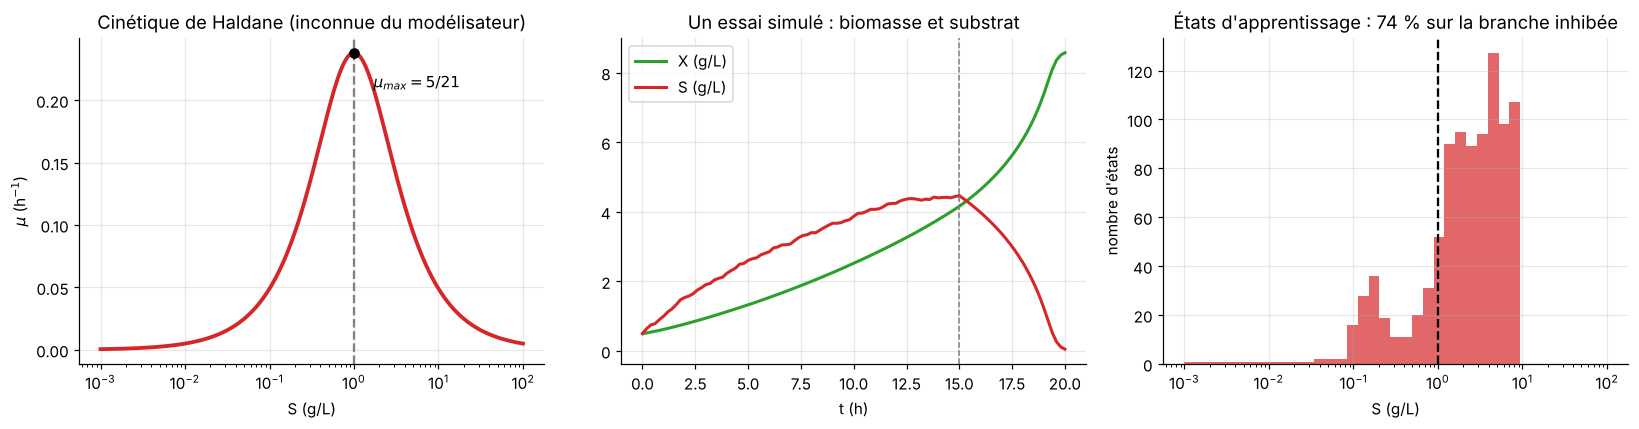

In [5]:
r = train_runs[4]      # essai de référence : (X0, S0) = (0,5 ; 0,5)
S_all = np.concatenate([q["S"][:-1] for q in train_runs]); Sg = np.logspace(-3, 2, 400)
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].plot(Sg, haldane(Sg), "C3", lw=2.5); ax[0].axvline(1, color="gray", ls="--"); ax[0].plot(1, P["mu_max"], "ko")
ax[0].set_xscale("log"); ax[0].set_xlabel("S (g/L)"); ax[0].set_ylabel(r"$\mu$ (h$^{-1}$)"); ax[0].annotate(r"$\mu_{max}=5/21$", (1, P["mu_max"]), (1.7, 0.21))
ax[0].set_title("Cinétique de Haldane (inconnue du modélisateur)")
ax[1].plot(r["t"], r["X"], "C2", lw=2, label="X (g/L)"); ax[1].plot(r["t"], r["S"], "C3", lw=2, label="S (g/L)"); ax[1].axvline(15, color="gray", ls="--", lw=1)
ax[1].set_xlabel("t (h)"); ax[1].set_title("Un essai simulé : biomasse et substrat"); ax[1].legend()
ax[2].hist(S_all, bins=np.logspace(-3, 2, 40), color="C3", alpha=0.7); ax[2].axvline(1, color="k", ls="--"); ax[2].set_xscale("log")
ax[2].set_xlabel("S (g/L)"); ax[2].set_ylabel("nombre d'états"); ax[2].set_title(f"États d'apprentissage : {100*np.mean(S_all > 1):.0f} % sur la branche inhibée")
plt.tight_layout(); plt.show()

**À retenir.**
- La cinétique de Haldane est très **pointue** : maximum de 5/21 ≈ 0,238 h⁻¹ à $S=1$ g/L, puis décroissance par inhibition (à $S=10$ g/L, $\mu\approx0{,}05$ h⁻¹).
- Avec $S_{in}\approx60$ g/L, le substrat monte vite au-delà de l'optimum : **74 % des états d'apprentissage sont sur la branche inhibée**, et 4 essais d'apprentissage sur 11 se bloquent (substrat > 1,5 g/L en fin d'essai). C'est une conséquence du protocole publié, pas un défaut du code. La branche limitée ($S<1$ g/L) est peu visitée.
- Sur l'essai de référence, la biomasse passe de 0,5 à 8,6 g/L en 20 h (l'alimentation s'arrête à 15 h).

---
# Partie 2 · Les points pseudo-expérimentaux

Le modélisateur ne voit jamais les états vrais. On leur ajoute un **bruit gaussien** d'écart-type $\sigma=0{,}1$ g/L sur $X$ et $S$ (lecture de $\mathcal N(0;0{,}01)$ comme variance), avec un plancher de mesure à $10^{-3}$ g/L ; $V$, $F$ et $S_{in}$ restent exacts. **Seules ces mesures bruitées servent à l'apprentissage** ; les états vrais ne servent qu'à l'évaluation.

Piège instructif : on ne peut pas « lire » $\mu$ dans les données. Le calcul naïf $\hat\mu\approx\frac{\ln X_{k+1}-\ln X_k}{\Delta t}+\frac FV$ est noyé par le bruit.

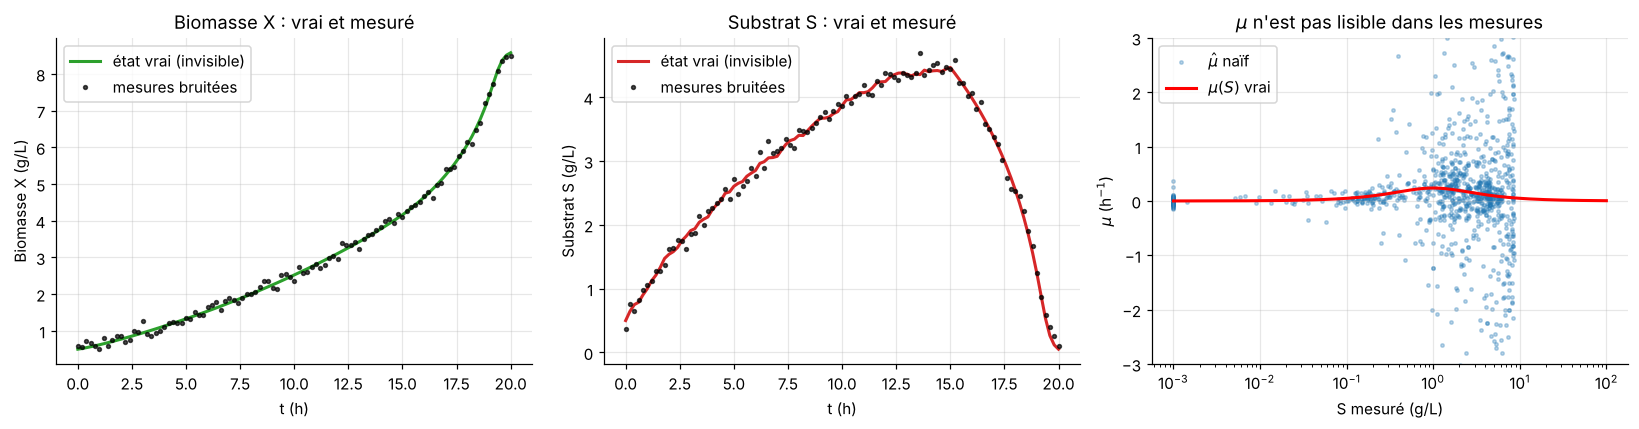

Erreur de l'estimation naïve de mu : écart-type 2.37 h^-1, pour un mu_max de 0.238 h^-1


In [6]:
mu_hat = np.concatenate([np.diff(np.log(q["Xm"])) / P["dt"] + q["F"] / q["V"][:-1] for q in train_runs])
S_meas = np.concatenate([q["Sm"][:-1] for q in train_runs]); mu_true = np.concatenate([haldane(q["S"][:-1]) for q in train_runs])
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for a, v, vm, nm, c in zip(ax[:2], ["X", "S"], ["Xm", "Sm"], ["Biomasse X", "Substrat S"], ["C2", "C3"]):
    a.plot(r["t"], r[v], color=c, lw=2, label="état vrai (invisible)"); a.plot(r["t"], r[vm], "k.", ms=5, alpha=0.7, label="mesures bruitées")
    a.set_xlabel("t (h)"); a.set_ylabel(nm + " (g/L)"); a.set_title(nm + " : vrai et mesuré"); a.legend()
ax[2].scatter(S_meas, mu_hat, s=5, alpha=0.3, color="C0", label=r"$\hat\mu$ naïf"); ax[2].plot(Sg, haldane(Sg), "r", lw=2, label=r"$\mu(S)$ vrai")
ax[2].set_xscale("log"); ax[2].set_ylim(-3, 3); ax[2].set_xlabel("S mesuré (g/L)"); ax[2].set_ylabel(r"$\mu$ (h$^{-1}$)"); ax[2].set_title(r"$\mu$ n'est pas lisible dans les mesures"); ax[2].legend(loc="upper left")
plt.tight_layout(); plt.show()
print(f"Erreur de l'estimation naïve de mu : écart-type {np.std(mu_hat - mu_true):.2f} h^-1, pour un mu_max de {P['mu_max']:.3f} h^-1")

**À retenir.**
- Le bruit de 0,1 g/L est faible devant $X$ en fin d'essai, mais **élevé devant $S$** dès que le substrat est consommé : sous 0,1 g/L environ, la mesure ne suit plus l'état vrai.
- Calculer $\mu$ par différences finies sur $X$ bruité donne une erreur de **2,4 h⁻¹ en écart-type, soit dix fois $\mu_{max}$** : $\mu$ n'est pas lisible dans les données. Il faut un modèle qui **intègre** les bilans sur toute la trajectoire.
- Sur les intervalles du jeu de test d'interpolation, $\mu X\Delta t$ est inférieur à $\sigma=0{,}1$ pour 73 % d'entre eux (42 % en extrapolation) : l'apprentissage à un pas voit très peu de $\mu$ (voir partie 7).

---
### Outils communs aux parties 3 à 7

Mêmes définitions partout : critère de l'article (éq. 10), **erreur à un pas** (entrées bruitées, cible = état vrai suivant) et **simulation libre** sur 20 h (départ de l'état initial imposé, aucune mesure ensuite, concentrations écrêtées à $10^{-3}$ g/L, RMSE contre l'état vrai). L'**oracle** (bilans + vraie cinétique) donne le plancher de bruit.

In [7]:
def patterns_of(runs):
    c = lambda key, sl: np.concatenate([q[key][sl] for q in runs])
    return dict(X=c("Xm", slice(None, -1)), S=c("Sm", slice(None, -1)), Sin=c("Sin", slice(None)), V=c("V", slice(None, -1)), F=c("F", slice(None)),
                T=np.column_stack([c("Xm", slice(1, None)), c("Sm", slice(1, None))]) / P["S_avg"])

def one_step_mse(runs, predict):
    c = lambda key, sl: np.concatenate([q[key][sl] for q in runs])
    Xh, Sh = predict(c("Xm", slice(None, -1)), c("Sm", slice(None, -1)), c("Sin", slice(None)), c("V", slice(None, -1)), c("F", slice(None)))
    return np.mean((Xh - c("X", slice(1, None)))**2 + (Sh - c("S", slice(1, None)))**2) / P["S_avg"]**2

def free_run(predict, run):
    n = len(run["F"]); Xs = np.zeros(n + 1); Ss = np.zeros(n + 1); Xs[0], Ss[0] = run["X"][0], run["S"][0]
    for k in range(n):
        a, b = predict(np.array([Xs[k]]), np.array([Ss[k]]), np.array([run["Sin"][k]]), np.array([run["V"][k]]), np.array([run["F"][k]]))
        Xs[k+1] = max(a[0], P["floor"]); Ss[k+1] = max(b[0], P["floor"])
    return Xs, Ss

def free_rmse(runs, predict):
    sims = [free_run(predict, q) for q in runs]
    ex = np.sqrt(np.mean(np.concatenate([s[0] - q["X"] for s, q in zip(sims, runs)])**2))
    es = np.sqrt(np.mean(np.concatenate([s[1] - q["S"] for s, q in zip(sims, runs)])**2))
    return ex, es, sims

def drift_max(runs, sims):
    out = []
    for q, (Xs, Ss) in zip(runs, sims):
        inv = (P["k1"] * Xs + Ss) * q["V"] - (P["k1"] * Xs[0] + Ss[0]) * q["V"][0]; inv[1:] -= np.cumsum(q["F"] * q["Sin"] * P["dt"]); out.append(np.max(np.abs(inv)))
    return max(out)

def oracle_factory(k1=1.0, kd=0.0):
    def f(x, s, si, V_, F_):
        mu = haldane(s); a = mu - kd; dt = P["dt"]; V1 = V_ + F_ * dt
        ratio = np.where(np.abs(a) > 1e-9, np.expm1(a * dt) / np.where(np.abs(a) > 1e-9, a, 1.0), dt)
        return x * np.exp(a * dt) * V_ / V1, (s * V_ + F_ * si * dt - k1 * mu * x * V_ * ratio) / V1
    return f

def split(n, seed):
    idx = np.random.default_rng(seed).permutation(n); n_tr = int(0.7 * n); return idx[:n_tr], idx[n_tr:]

dtr = patterns_of(train_runs); N = len(dtr["X"]); oracle = oracle_factory()
ref = dict(os_i=one_step_mse(test_i, oracle), os_e=one_step_mse(test_e, oracle), fr_i=free_rmse(test_i, oracle)[0], fr_e=free_rmse(test_e, oracle)[0])
print("Oracle (plancher de bruit) : MSE à un pas %.1e / %.1e ; RMSE de X en simulation libre %.3f / %.3f g/L" % (ref["os_i"], ref["os_e"], ref["fr_i"], ref["fr_e"]))

Oracle (plancher de bruit) : MSE à un pas 5.0e-06 / 4.9e-06 ; RMSE de X en simulation libre 0.036 / 0.027 g/L


---
# Partie 3 · La voie « IA pure »

Un réseau boîte noire **3→8→2** prédit directement l'état suivant, **sans physique** : entrées $\ln X$, $\ln S$, $S_{in}/S_{avg}$ ($S_{avg}=60$ g/L), sorties $(X,S)_{k+1}/S_{avg}$ ; il ne reçoit ni $F$ ni $V$, comme dans l'article. Critère éq. 10, Adam (taux 0,02), apprentissage par lot, partage 70/30 avec arrêt anticipé (contrôle toutes les 10 époques, patience 40, 30 000 époques au maximum).

IA pure : meilleur réseau à l'époque 11570
            MSE 1 pas interp  MSE 1 pas extrap  RMSE X libre interp  RMSE X libre extrap
IA pure              6.2e-06           2.5e-04                 2.87                 2.99
Oracle               5.0e-06           4.9e-06                 0.04                 0.03
Dérive de la matière de l'IA pure : 63 g (interp), 76 g (extrap), pour environ 90 g injectés


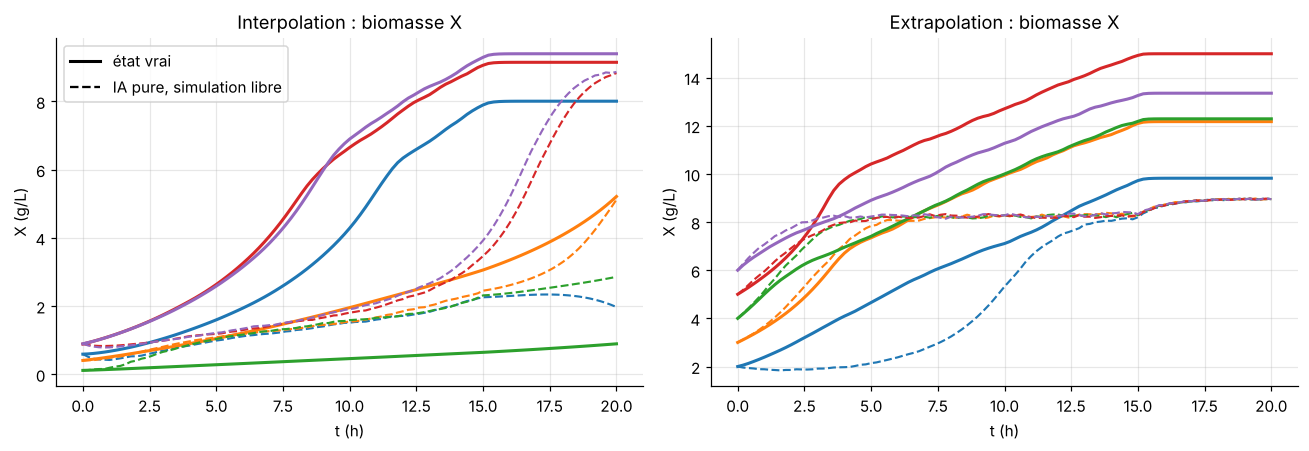

In [8]:
tr0, va0 = split(N, 0)
bb = BlackBox(0); h_bb, ep_bb, _ = train_model(bb, dtr, tr0, va0)
res3 = {nm: (one_step_mse(test_i, pr), one_step_mse(test_e, pr), *free_rmse(test_i, pr)[:1], *free_rmse(test_e, pr)[:1])
        for nm, pr in (("IA pure", bb.predict), ("Oracle", oracle))}
sims_i, sims_e = free_rmse(test_i, bb.predict)[2], free_rmse(test_e, bb.predict)[2]
print(f"IA pure : meilleur réseau à l'époque {ep_bb}")
print(f"{'':<10}{'MSE 1 pas interp':>18}{'MSE 1 pas extrap':>18}{'RMSE X libre interp':>21}{'RMSE X libre extrap':>21}")
for nm, v in res3.items(): print(f"{nm:<10}{v[0]:>18.1e}{v[1]:>18.1e}{v[2]:>21.2f}{v[3]:>21.2f}")
print(f"Dérive de la matière de l'IA pure : {drift_max(test_i, sims_i):.0f} g (interp), {drift_max(test_e, sims_e):.0f} g (extrap), pour environ 90 g injectés")

fig, ax = plt.subplots(1, 2, figsize=(12, 4.2), sharey=False)
for a, runs, sims, ttl in [(ax[0], test_i, sims_i, "Interpolation"), (ax[1], test_e, sims_e, "Extrapolation")]:
    for j, (q, s) in enumerate(zip(runs, sims)):
        a.plot(q["t"], q["X"], color=f"C{j}", lw=2); a.plot(q["t"], s[0], "--", color=f"C{j}", lw=1.4)
    a.set_title(ttl + " : biomasse X"); a.set_xlabel("t (h)"); a.set_ylabel("X (g/L)")
ax[0].plot([], [], "k-", lw=2, label="état vrai"); ax[0].plot([], [], "k--", label="IA pure, simulation libre"); ax[0].legend()
plt.tight_layout(); plt.show()

**À retenir.**
- **À un pas, l'IA pure est au niveau du bruit en interpolation** (6,2·10⁻⁶ contre 5,0·10⁻⁶ pour l'oracle) : cette métrique ne révèle aucun problème dans le domaine d'apprentissage. Elle décroche en extrapolation (2,5·10⁻⁴, soixante fois le plancher).
- **En simulation libre sur 20 h, elle échoue** : erreur sur $X$ de 2,9 g/L en interpolation et 3,0 g/L en extrapolation, contre 0,04 et 0,03 pour l'oracle. Elle rate les essais bloqués par l'inhibition, et la biomasse **plafonne vers 8–9 g/L**, le maximum vu à l'apprentissage, alors que la vraie monte jusqu'à 15 g/L.
- **Elle ne conserve pas la matière** : dérive de 63 g (interpolation) à 76 g (extrapolation), pour environ 90 g injectés.
- Convergence lente : meilleur réseau à l'époque 11 570.

---
# Partie 4 · L'hybride série

Dans l'**hybride série** (Psichogios et Ungar), les bilans de matière sont conservés **tels quels** ; un réseau **2→8→1** (entrées $\ln X$, $\ln S$) n'apprend que $\mu$, avec $\mu=2\mu_{max}\tilde\mu$, $\tilde\mu\in(-1;1)$. Le réseau ne voit jamais $\mu$ : il est entraîné **à travers** les bilans, en rétropropageant l'erreur sur $(X,S)$ via les sensibilités analytiques $G_1=\partial X_1/\partial\mu=X_1\Delta t$ et $G_2=\partial S_1/\partial\mu=-k_1XV\Delta t\,e^{\mu\Delta t}/V_1$ (pas de temps analytique, $\mu$ constant sur 0,2 h). Même critère, même optimiseur, mêmes jeux de test qu'en partie 3.

Repère supplémentaire : la **connaissance seule** (bilans + loi de **Monod** $\mu_mS/(K_s+S)$ identifiée par moindres carrés, sans réseau).

Monod identifié : mu_m = 0.164 h^-1, K_s = 0.180 g/L ; hybride : meilleur réseau à l'époque 160 (IA pure : 11570)
                  MSE 1 pas interp  MSE 1 pas extrap  RMSE X libre interp  RMSE X libre extrap
Monod seul                 5.4e-06           5.1e-06                 1.44                 0.36
IA pure                    6.2e-06           2.5e-04                 2.87                 2.99
Hybride série              4.9e-06           5.4e-06                 0.82                 0.05
Oracle                     5.0e-06           4.9e-06                 0.04                 0.03
Dérive de la matière de l'hybride (sans écrêtage) : bilans exacts => conservation par construction ; avec écrêtage : 0.27 g (interp)


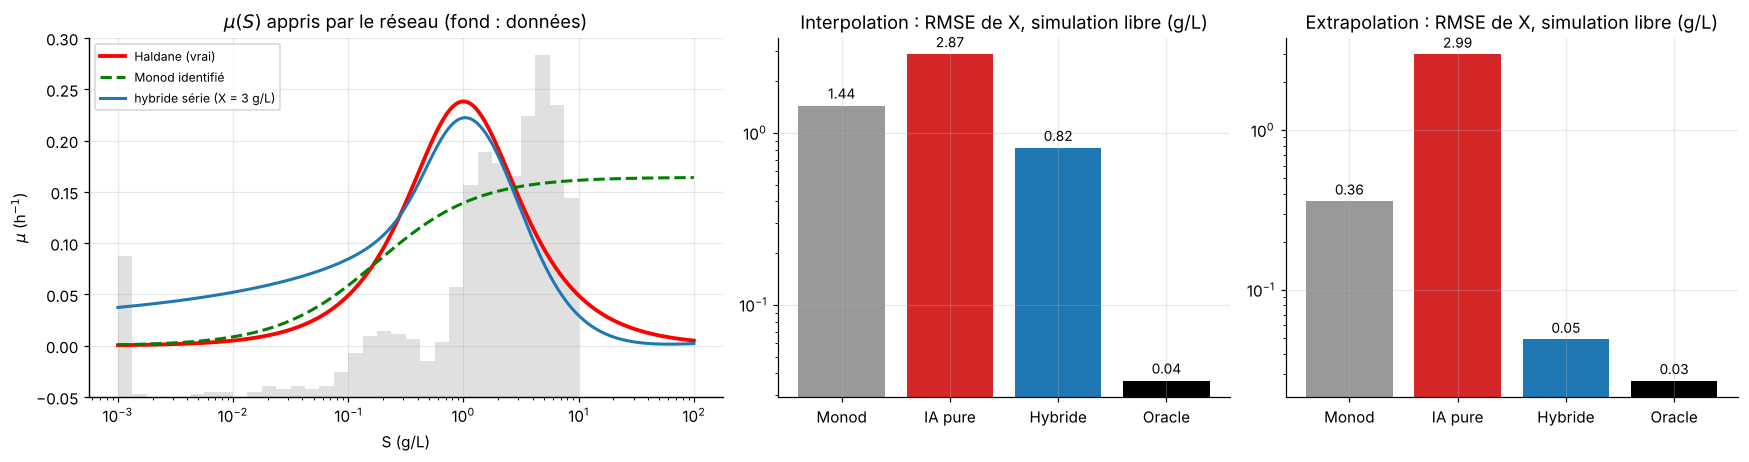

In [9]:
mc0 = fit_monod(dtr); mm, Ks = mc0
hyb = HybridSerie(0); h_hyb, ep_hyb, _ = train_model(hyb, dtr, tr0, va0)
models4 = {"Monod seul": lambda x, s, si, V_, F_: step_phys(x, s, V_, F_, si, monod(s, mm, Ks))[:2], "IA pure": bb.predict,
           "Hybride série": hyb.predict, "Oracle": oracle}
R4 = {nm: dict(os_i=one_step_mse(test_i, pr), os_e=one_step_mse(test_e, pr), fi=free_rmse(test_i, pr), fe=free_rmse(test_e, pr)) for nm, pr in models4.items()}
print(f"Monod identifié : mu_m = {mm:.3f} h^-1, K_s = {Ks:.3f} g/L ; hybride : meilleur réseau à l'époque {ep_hyb} (IA pure : {ep_bb})")
print(f"{'':<16}{'MSE 1 pas interp':>18}{'MSE 1 pas extrap':>18}{'RMSE X libre interp':>21}{'RMSE X libre extrap':>21}")
for nm, v in R4.items(): print(f"{nm:<16}{v['os_i']:>18.1e}{v['os_e']:>18.1e}{v['fi'][0]:>21.2f}{v['fe'][0]:>21.2f}")
hs = hyb.predict
print(f"Dérive de la matière de l'hybride (sans écrêtage) : bilans exacts => conservation par construction ; avec écrêtage : {drift_max(test_i, R4['Hybride série']['fi'][2]):.2f} g (interp)")

Sx = np.logspace(-3, 2, 400); cols = {"Monod seul": "0.6", "IA pure": "C3", "Hybride série": "C0", "Oracle": "k"}
fig, ax = plt.subplots(1, 3, figsize=(16, 4.3), gridspec_kw=dict(width_ratios=[1.4, 1, 1]))
ax2 = ax[0].twinx(); ax2.hist(dtr["S"], bins=np.logspace(-3, 2, 41), color="0.88", zorder=0); ax2.set_yticks([]); ax2.grid(False)
ax[0].set_zorder(ax2.get_zorder() + 1); ax[0].patch.set_visible(False)
ax[0].plot(Sx, haldane(Sx), "r", lw=2.5, label="Haldane (vrai)"); ax[0].plot(Sx, monod(Sx, mm, Ks), "g--", lw=2, label="Monod identifié")
ax[0].plot(Sx, hyb.mu(np.full_like(Sx, 3.0), Sx), "C0", lw=2, label="hybride série (X = 3 g/L)")
ax[0].set_xscale("log"); ax[0].set_ylim(-0.05, 0.3); ax[0].set_xlabel("S (g/L)"); ax[0].set_ylabel(r"$\mu$ (h$^{-1}$)"); ax[0].legend(fontsize=8, loc="upper left")
ax[0].set_title(r"$\mu(S)$ appris par le réseau (fond : données)")
for a, key, ttl in [(ax[1], "fi", "Interpolation"), (ax[2], "fe", "Extrapolation")]:
    vals = [R4[n][key][0] for n in models4]; a.bar(range(4), vals, color=[cols[n] for n in models4])
    a.set_yscale("log"); a.set_xticks(range(4)); a.set_xticklabels(["Monod", "IA pure", "Hybride", "Oracle"])
    for i, v_ in enumerate(vals): a.text(i, v_ * 1.1, f"{v_:.2f}", ha="center", fontsize=9)
    a.set_title(f"{ttl} : RMSE de X, simulation libre (g/L)")
plt.tight_layout(); plt.show()

**À retenir.**

| RMSE de $X$ en simulation libre (g/L) | Monod seul | IA pure | **Hybride série** | Oracle |
|---|---|---|---|---|
| Interpolation | 1,44 | 2,87 | **0,82** | 0,04 |
| Extrapolation | 0,36 | 2,99 | **0,05** | 0,03 |

- Le réseau, sans jamais voir $\mu$, retrouve la **forme de Haldane** : pic vers 1 g/L (0,22 pour un vrai pic de 0,238) et inhibition. Monod, lui, plafonne à 0,16 h⁻¹. Le réseau reste imparfait là où les données sont rares ou noyées dans le bruit (très faibles $S$).
- **50 fois moins d'époques** que l'IA pure (160 contre 11 570) : une seule fonction scalaire à apprendre.
- **Conservation de la matière par construction** : dérive de l'ordre de 10⁻¹³ g sans écrêtage (0,27 g avec écrêtage des concentrations négatives, un artefact de simulation).
- **L'erreur à un pas ne départage presque pas les modèles** (4,9·10⁻⁶ à 6,2·10⁻⁶ en interpolation) : seule la simulation libre le fait.
- C'est un **meilleur cas** : les bilans du modèle sont exactement ceux du simulateur (voir partie 7).

---
# Partie 5 · Effet de la taille du jeu

Pour $N\in\{50,100,250,500,1000\}$ et chacune des `N_SESS` sessions : $N$ patterns tirés au hasard parmi les 1000, partage 70/30, **mêmes patterns pour les deux modèles** (rapports appariés), initialisations différentes ; évaluation sur les mêmes jeux de test. On compare l'IA pure et l'hybride série.

Rapport IA pure / hybride (médiane, appariée), rapports > 1 : l'hybride est meilleur
     N  1 pas interp  1 pas extrap  libre interp  libre extrap
    50         37.0x        152.9x          1.1x          6.5x
   100          7.7x         52.3x          2.3x         13.9x
   250          2.1x         71.6x          2.5x         19.0x
   500          1.6x         53.9x          1.9x         22.9x
  1000          1.4x         54.9x          3.3x         37.0x


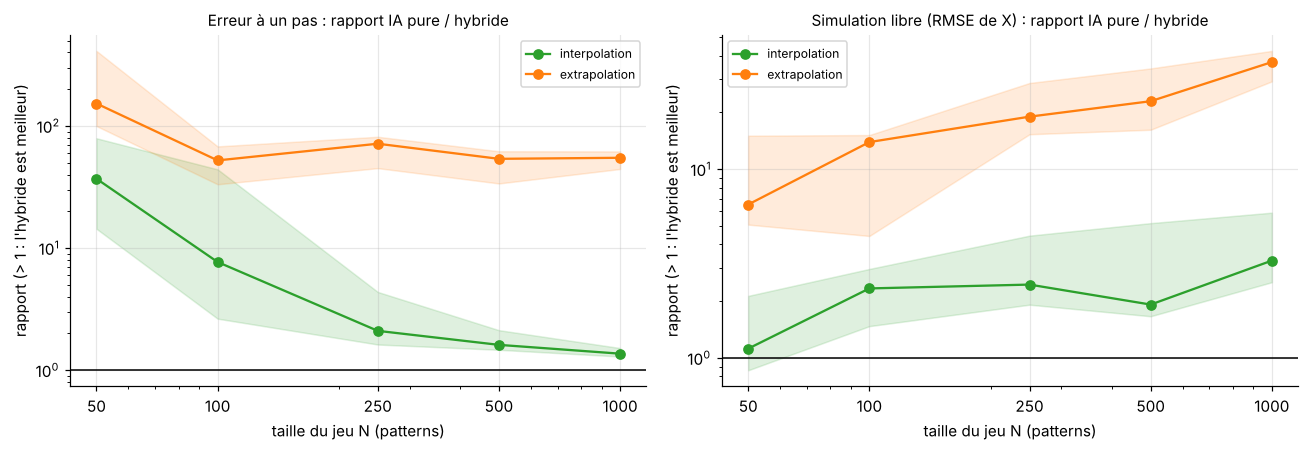

In [10]:
SIZES = [50, 100, 250, 500, 1000]; rec5 = []
for n_sub in SIZES:
    for sd in range(N_SESS):
        sub = np.random.default_rng(100 * sd + n_sub).permutation(N)[:n_sub]
        d = {k: v[sub] for k, v in dtr.items()}; tr_, va_ = split(n_sub, sd); row = [n_sub, sd]; nets = []
        for cls in (HybridSerie, BlackBox):
            nt = cls(sd); train_model(nt, d, tr_, va_); nets.append(nt)
        for runs in (test_i, test_e):
            row += [one_step_mse(runs, nets[0].predict), one_step_mse(runs, nets[1].predict), free_rmse(runs, nets[0].predict)[0], free_rmse(runs, nets[1].predict)[0]]
        rec5.append(row)
rec5 = np.array(rec5)      # colonnes : N, sess, [os_h, os_b, fr_h, fr_b] interp, [os_h, os_b, fr_h, fr_b] extrap
def ratio5(n_sub, jb, jh):
    r_ = rec5[rec5[:, 0] == n_sub]; q = r_[:, jb] / r_[:, jh]; return np.median(q), np.percentile(q, 25), np.percentile(q, 75)
print("Rapport IA pure / hybride (médiane, appariée), rapports > 1 : l'hybride est meilleur")
print(f"{'N':>6}{'1 pas interp':>14}{'1 pas extrap':>14}{'libre interp':>14}{'libre extrap':>14}")
for n_sub in SIZES:
    print(f"{n_sub:>6}" + "".join(f"{ratio5(n_sub, jb, jh)[0]:>13.1f}x" for jb, jh in [(3, 2), (7, 6), (5, 4), (9, 8)]))

fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
for a, pairs, ttl in [(ax[0], [((3, 2), "C2", "interpolation"), ((7, 6), "C1", "extrapolation")], "Erreur à un pas : rapport IA pure / hybride"),
                      (ax[1], [((5, 4), "C2", "interpolation"), ((9, 8), "C1", "extrapolation")], "Simulation libre (RMSE de X) : rapport IA pure / hybride")]:
    for (jb, jh), c, nm in pairs:
        q = np.array([ratio5(n_sub, jb, jh) for n_sub in SIZES]); a.plot(SIZES, q[:, 0], "o-", color=c, label=nm); a.fill_between(SIZES, q[:, 1], q[:, 2], color=c, alpha=0.15)
    a.axhline(1, color="k", lw=1); a.set_xscale("log"); a.set_yscale("log"); a.set_xticks(SIZES); a.set_xticklabels(SIZES)
    a.set_xlabel("taille du jeu N (patterns)"); a.set_ylabel("rapport (> 1 : l'hybride est meilleur)"); a.set_title(ttl, fontsize=10); a.legend(fontsize=8)
plt.tight_layout(); plt.show()

**À retenir** (rapports IA pure / hybride, médianes appariées ; > 1 : l'hybride est meilleur).

| $N$ | 50 | 100 | 250 | 500 | 1000 |
|---|---|---|---|---|---|
| Erreur à un pas, interpolation | ×37 | ×7,7 | ×2,1 | ×1,6 | **×1,4** |
| Erreur à un pas, extrapolation | ×153 | ×52 | ×72 | ×54 | ×55 |
| Simulation libre, interpolation | ×1,1 | ×2,3 | ×2,5 | ×1,9 | **×3,3** |
| Simulation libre, extrapolation | ×6,5 | ×14 | ×19 | ×23 | **×37** |

- **À un pas, l'avantage de l'hybride fond avec $N$** : avec assez de données bien réparties, l'IA pure s'approche du niveau de bruit dans le domaine d'apprentissage. C'est le message attendu ; l'écart est bien plus faible que l'ordre de grandeur annoncé en 1992 dès que le jeu dépasse quelques centaines de points.
- **En simulation libre, l'avantage ne disparaît pas, il grandit** : à 1000 points l'IA pure reste à ≈ 3 g/L d'erreur, parce que de petites erreurs à chaque pas s'accumulent sur 20 h. **Le critère d'évaluation change la conclusion.**
- **Hors domaine, l'avantage est massif et indépendant de $N$** à un pas.
- **Attention aux très petits jeux** ($N=50$) : l'hybride n'est pas meilleur que l'IA pure en interpolation (×1,1) ; il apprend une cinétique sans inhibition. Avoir la bonne physique ne remplace pas l'information sur $\mu$.

---
# Partie 6 · Influence de l'architecture (Shah et al. 2025, fig. 3)

```
A  série MC→IA :  entrées ─► bilans + Monod ─► (X̃, S̃) ─► réseau ─► (X, S)
B  série IA→MC :  (ln X, ln S) ─► réseau ─► μ ─► bilans ─► (X, S)           (B′ : entrée S seule)
C  parallèle     :  entrées ─┬─► bilans + Monod ──────────────┬─► + ─► (X, S)
                             └─► réseau (résidu, ±10 g/L) ────┘
```
Pour A et C, le modèle de connaissance (MC) est **Monod identifié** (volontairement imparfait). Comparaison à $N=1000$ sur `N_SESS` sessions, avec l'IA pure et Monod seul comme repères.

N = 1000, médianes           RMSE X interp  RMSE X extrap   dérive matière max (g)
B  série IA→MC                        0.84           0.08                  4.4e-02
B' série, entrée S seule              0.51           0.07                  3.0e-01
A  série MC→IA                        1.97           3.00                  7.9e+01
C  parallèle                          1.29           0.95                  3.3e+01
Monod seul                            1.44           0.36                  1.7e+00
IA pure                               2.92           2.98                  7.7e+01
Oracle                                0.04           0.03                  9.1e-01


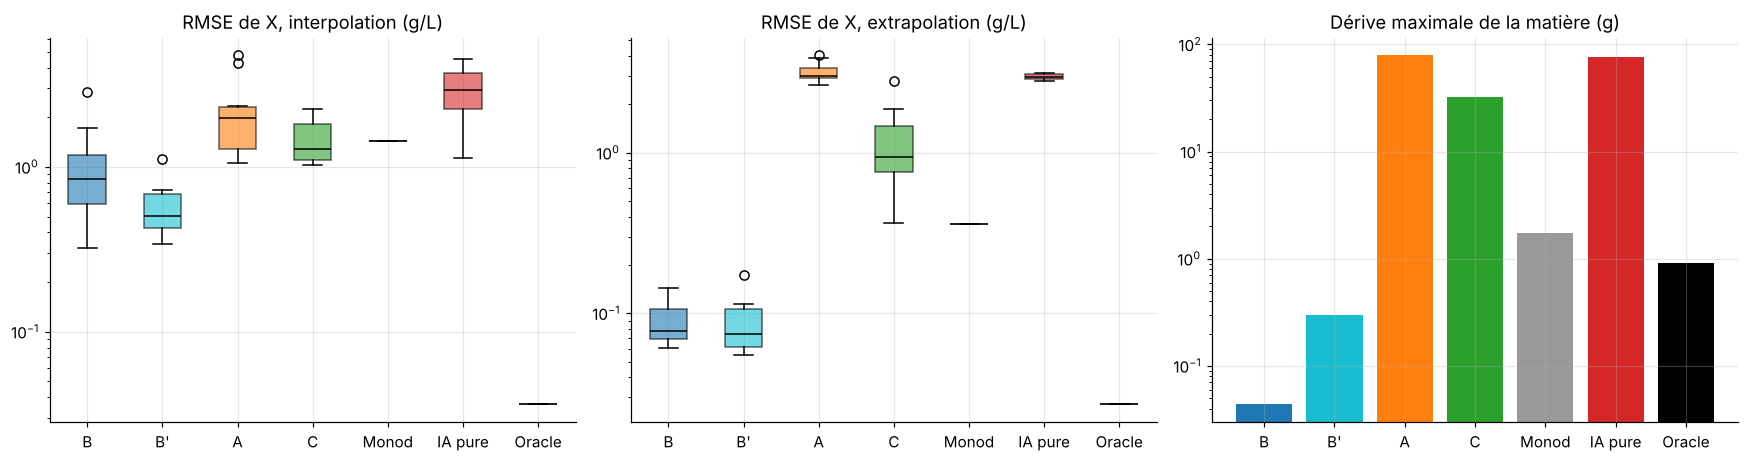

In [11]:
ARCH = ["B  série IA→MC", "B' série, entrée S seule", "A  série MC→IA", "C  parallèle", "Monod seul", "IA pure", "Oracle"]
res6 = {a: [] for a in ARCH}
for sd in range(N_SESS):
    sub = np.random.default_rng(100 * sd + 1000).permutation(N)[:1000]; d = {k: v[sub] for k, v in dtr.items()}; tr_, va_ = split(1000, sd)
    mc = fit_monod(d); pr = {}
    for nm, cls in (("B  série IA→MC", HybridSerie), ("B' série, entrée S seule", HybridSerieS)):
        nt = cls(sd); train_model(nt, d, tr_, va_); pr[nm] = nt.predict
    nA = SerieMCtoIA(sd, mc); dA = dict(Z=nA.feats(d["X"], d["S"], d["Sin"], d["V"], d["F"]), T=d["T"]); train_model(nA, dA, tr_, va_); pr["A  série MC→IA"] = nA.predict
    nC = Parallele(sd, mc); Xt, St, _ = step_phys(d["X"], d["S"], d["V"], d["F"], d["Sin"], monod(d["S"], *mc))
    dC = dict(Z=nC.feats(d["X"], d["S"], d["Sin"], d["V"], d["F"]), T=np.column_stack([np.clip((d["T"][:, 0] * P["S_avg"] - Xt) / R_MAX, -.999, .999), np.clip((d["T"][:, 1] * P["S_avg"] - St) / R_MAX, -.999, .999)]))
    train_model(nC, dC, tr_, va_); pr["C  parallèle"] = nC.predict
    pr["Monod seul"] = lambda x, s, si, V_, F_, f=mc: step_phys(x, s, V_, F_, si, monod(s, *f))[:2]
    nb_ = BlackBox(sd); train_model(nb_, d, tr_, va_); pr["IA pure"] = nb_.predict; pr["Oracle"] = oracle
    for a in ARCH:
        ri, re_ = free_rmse(test_i, pr[a]), free_rmse(test_e, pr[a])
        res6[a].append([ri[0], re_[0], max(drift_max(test_i, ri[2]), drift_max(test_e, re_[2]))])
res6 = {a: np.array(v) for a, v in res6.items()}
print(f"{'N = 1000, médianes':<27}{'RMSE X interp':>15}{'RMSE X extrap':>15}{'dérive matière max (g)':>25}")
for a in ARCH: print(f"{a:<27}{np.median(res6[a][:,0]):>15.2f}{np.median(res6[a][:,1]):>15.2f}{np.median(res6[a][:,2]):>25.1e}")

colors6 = {"B  série IA→MC": "C0", "B' série, entrée S seule": "C9", "A  série MC→IA": "C1", "C  parallèle": "C2", "Monod seul": "0.6", "IA pure": "C3", "Oracle": "k"}
short6 = {"B  série IA→MC": "B", "B' série, entrée S seule": "B'", "A  série MC→IA": "A", "C  parallèle": "C", "Monod seul": "Monod", "IA pure": "IA pure", "Oracle": "Oracle"}
fig, ax = plt.subplots(1, 3, figsize=(16, 4.3))
for a_, j, ttl in [(ax[0], 0, "RMSE de X, interpolation (g/L)"), (ax[1], 1, "RMSE de X, extrapolation (g/L)")]:
    bp = a_.boxplot([res6[a][:, j] for a in ARCH], patch_artist=True, medianprops=dict(color="k"))
    for patch, a in zip(bp["boxes"], ARCH): patch.set_facecolor(colors6[a]); patch.set_alpha(0.6)
    a_.set_yscale("log"); a_.set_xticks(range(1, 8)); a_.set_xticklabels([short6[a] for a in ARCH]); a_.set_title(ttl)
vals = [max(np.median(res6[a][:, 2]), 1e-14) for a in ARCH]; ax[2].bar(range(7), vals, color=[colors6[a] for a in ARCH])
ax[2].set_yscale("log"); ax[2].set_xticks(range(7)); ax[2].set_xticklabels([short6[a] for a in ARCH]); ax[2].set_title("Dérive maximale de la matière (g)")
plt.tight_layout(); plt.show()

**À retenir** ($N=1000$, médianes).

| Architecture | RMSE de $X$ (interp / extrap, g/L) | Matière | Verdict |
|---|---|---|---|
| **B′** série IA→MC, entrée $S$ seule | **0,51 / 0,07** | conservée | meilleure |
| **B** série IA→MC | 0,84 / 0,08 | conservée | très bonne |
| **C** parallèle | 1,29 / 0,95 | **dérive de 33 g** | correcte dans le domaine, mauvaise hors domaine |
| Monod seul | 1,44 / 0,36 | conservée | repère solide |
| **A** série MC→IA | 1,97 / 3,00 | **dérive de 79 g** | proche de l'IA pure |
| IA pure | 2,92 / 2,98 | dérive de 77 g | – |

- **Où l'on met le réseau compte plus que le fait d'en mettre un.** B apprend uniquement la fonction inconnue, *à l'intérieur* de la structure ; A et C laissent le réseau modifier les **sorties**, donc pouvoir violer la physique.
- Un hybride mal conçu peut faire **moins bien que sa propre physique** (C à petit $N$ et hors domaine : 0,95 contre 0,36 pour Monod seul en extrapolation).
- **Réduire le réseau à ce qu'on ne sait pas** (B′ : $\mu$ ne dépend que de $S$) améliore encore l'interpolation de 40 % : de la connaissance injectée dans l'architecture vaut des données.
- La conservation de la matière est une propriété de l'architecture : la dérive de B (0,04 g) vient uniquement de l'écrêtage des concentrations, comme celle de l'oracle (0,9 g).

---
# Partie 7 · Risques et limites

Trois familles de risques, testées chacune avec les architectures B, B′, C, l'IA pure, Monod seul et un oracle qui connaît la vraie physique :

| Scénario | Ce qui change |
|---|---|
| **Mortalité** $k_d=0{,}05$ h⁻¹ | monde réel : $dX/dt=\mu X-k_dX-\frac FVX$ ; **les modèles gardent leurs bilans d'origine** |
| **Rendement** $k_1=1{,}3$ | idem, avec $dS/dt=-1{,}3\,\mu X+\dots$ |
| **Bruit fort** $\sigma=0{,}3$ g/L | le signal sur $\mu$ s'efface |
| **Domaine** | apprentissage restreint à $S\le1{,}2$ g/L ; test hors domaine à $S_0=5,10,20$ g/L |

In [12]:
SCEN = {"Référence": dict(k1=1.0, kd=0.0, sigma=0.1, restrict=False), "Bruit 0,3": dict(k1=1.0, kd=0.0, sigma=0.3, restrict=False),
        "Mortalité": dict(k1=1.0, kd=0.05, sigma=0.1, restrict=False), "Rendement k1=1,3": dict(k1=1.3, kd=0.0, sigma=0.1, restrict=False),
        "Domaine S≤1,2": dict(k1=1.0, kd=0.0, sigma=0.1, restrict=True)}
M7 = ["B  série IA→MC", "B' série, entrée S seule", "C  parallèle", "IA pure", "Monod seul", "Oracle"]
store7 = {}
for sc, cfg in SCEN.items():
    trn = gen_train(cfg["k1"], cfg["kd"], cfg["sigma"]); ti_ = gen_test_i(cfg["k1"], cfg["kd"], cfg["sigma"]); te_ = gen_test_e(cfg["k1"], cfg["kd"], cfg["sigma"])
    to_ = gen_test_o() if cfg["restrict"] else None; d = patterns_of(trn)
    if cfg["restrict"]:
        keep_ = np.where(d["S"] <= 1.2)[0]; d = {k: v[keep_] for k, v in d.items()}; print(f"Domaine restreint : {len(keep_)} patterns conservés sur 1000")
    n = len(d["X"]); orc = oracle_factory(cfg["k1"], cfg["kd"]); rows = {m: [] for m in M7}
    for sd in range(N_SESS):
        tr_, va_ = split(n, sd); mc = fit_monod(d); pr = {}
        for nm, cls in (("B  série IA→MC", HybridSerie), ("B' série, entrée S seule", HybridSerieS)):
            nt = cls(sd); train_model(nt, d, tr_, va_); pr[nm] = nt.predict
        nC = Parallele(sd, mc); Xt, St, _ = step_phys(d["X"], d["S"], d["V"], d["F"], d["Sin"], monod(d["S"], *mc))
        dC = dict(Z=nC.feats(d["X"], d["S"], d["Sin"], d["V"], d["F"]), T=np.column_stack([np.clip((d["T"][:, 0] * P["S_avg"] - Xt) / R_MAX, -.999, .999), np.clip((d["T"][:, 1] * P["S_avg"] - St) / R_MAX, -.999, .999)]))
        train_model(nC, dC, tr_, va_); pr["C  parallèle"] = nC.predict
        nb_ = BlackBox(sd); train_model(nb_, d, tr_, va_); pr["IA pure"] = nb_.predict
        pr["Monod seul"] = lambda x, s, si, V_, F_, f=mc: step_phys(x, s, V_, F_, si, monod(s, *f))[:2]; pr["Oracle"] = orc
        for m in M7:
            row = [one_step_mse(ti_, pr[m]), free_rmse(ti_, pr[m])[0], free_rmse(te_, pr[m])[0], np.nan, np.nan]
            if to_ is not None: ro = free_rmse(to_, pr[m]); row[3:5] = [ro[0], ro[1]]
            rows[m].append(row)
    for m in M7: store7[(sc, m)] = np.array(rows[m])
    print(f"{sc} : terminé")
med7 = lambda sc, m, j: np.median(store7[(sc, m)][:, j])
print(f"\n{'RMSE de X en simulation libre (g/L), médianes':<47}" + "".join(f"{s:>20}" for s in SCEN))
for lab, j in [("interpolation", 1), ("extrapolation", 2)]:
    for m in M7: print(f"{lab + ' – ' + m:<47}" + "".join(f"{med7(s, m, j):>20.2f}" for s in SCEN))
print("\nHors domaine (S0 = 5, 10, 20 g/L) : RMSE de S (g/L) : " + ", ".join(f"{m.split('  ')[-1]} {med7('Domaine S≤1,2', m, 4):.1f}" for m in M7))
print("Facteur de dégradation en extrapolation vs Référence : " + "; ".join(f"{sc}: " + ", ".join(f"{m.split('  ')[-1]} x{med7(sc, m, 2)/med7('Référence', m, 2):.1f}" for m in M7[:5]) for sc in ["Mortalité", "Rendement k1=1,3"]))

Référence : terminé


Bruit 0,3 : terminé


Mortalité : terminé


Rendement k1=1,3 : terminé


Domaine restreint : 298 patterns conservés sur 1000


Domaine S≤1,2 : terminé

RMSE de X en simulation libre (g/L), médianes             Référence           Bruit 0,3           Mortalité    Rendement k1=1,3       Domaine S≤1,2
interpolation – B  série IA→MC                                 0.62                3.81                1.00                1.08                1.29
interpolation – B' série, entrée S seule                       0.36                1.53                0.91                1.13                2.01
interpolation – C  parallèle                                   1.46                4.52                1.40                1.44                2.89
interpolation – IA pure                                        2.62                4.51                2.67                2.38                4.14
interpolation – Monod seul                                     1.44                1.54                1.35                1.43                2.50
interpolation – Oracle                                         0.04                0.04

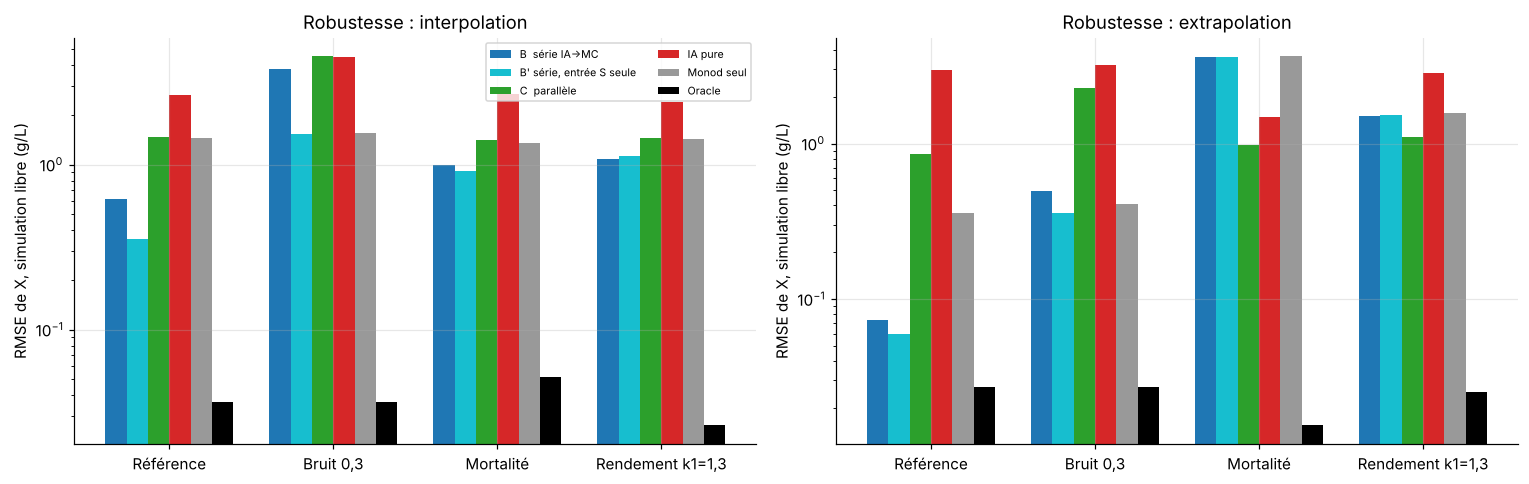

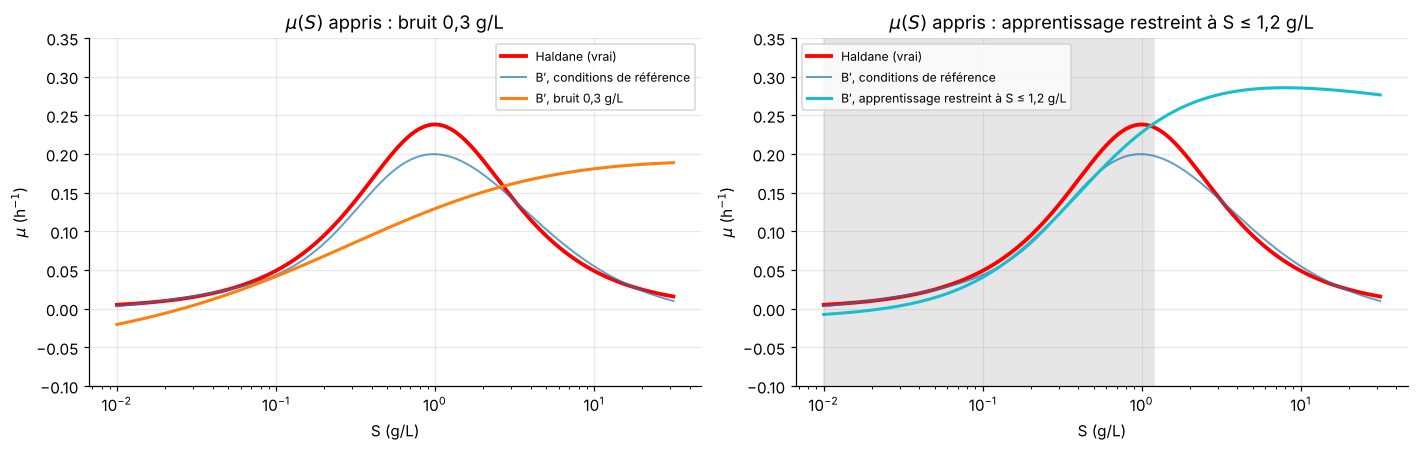

In [13]:
colors7 = {"B  série IA→MC": "C0", "B' série, entrée S seule": "C9", "C  parallèle": "C2", "IA pure": "C3", "Monod seul": "0.6", "Oracle": "k"}
scs = list(SCEN)[:4]
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
for a_, j, ttl in [(ax[0], 1, "interpolation"), (ax[1], 2, "extrapolation")]:
    w = 0.13
    for k, m in enumerate(M7): a_.bar(np.arange(len(scs)) + (k - 2.5) * w, [med7(sc, m, j) for sc in scs], w, color=colors7[m], label=m)
    a_.set_yscale("log"); a_.set_xticks(range(len(scs))); a_.set_xticklabels(scs); a_.set_ylabel("RMSE de X, simulation libre (g/L)"); a_.set_title(f"Robustesse : {ttl}")
ax[0].legend(fontsize=7, ncol=2)
plt.tight_layout(); plt.show()

Sh_ = np.logspace(-2, 1.5, 300); fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
cfg = SCEN["Bruit 0,3"]; dn = patterns_of(gen_train(cfg["k1"], cfg["kd"], cfg["sigma"])); tr_, va_ = split(len(dn["X"]), 0)
nt_noise = HybridSerieS(0); train_model(nt_noise, dn, tr_, va_)
mask = dtr["S"] <= 1.2; dd = {k: v[mask] for k, v in dtr.items()}; tr_, va_ = split(mask.sum(), 0); nt_dom = HybridSerieS(0); train_model(nt_dom, dd, tr_, va_)
nt_ref = HybridSerieS(0); train_model(nt_ref, dtr, tr0, va0)
for a_, nt, c, ttl in [(ax[0], nt_noise, "C1", "bruit 0,3 g/L"), (ax[1], nt_dom, "C9", "apprentissage restreint à S ≤ 1,2 g/L")]:
    a_.plot(Sh_, haldane(Sh_), "r", lw=2.5, label="Haldane (vrai)"); a_.plot(Sh_, nt_ref.mu(np.full_like(Sh_, 3.0), Sh_), "C0", lw=1.3, alpha=0.7, label="B′, conditions de référence")
    a_.plot(Sh_, nt.mu(np.full_like(Sh_, 3.0), Sh_), color=c, lw=2, label="B′, " + ttl); a_.set_xscale("log"); a_.set_ylim(-0.1, 0.35)
    a_.set_xlabel("S (g/L)"); a_.set_ylabel(r"$\mu$ (h$^{-1}$)"); a_.legend(fontsize=8); a_.set_title(r"$\mu(S)$ appris : " + ttl)
ax[1].axvspan(1e-2, 1.2, color="0.9", zorder=0)
plt.tight_layout(); plt.show()

**À retenir** (RMSE de $X$ en simulation libre, médianes ; extrapolation sauf mention).

| Scénario | B | B′ | C | IA pure | Monod seul | Oracle |
|---|---|---|---|---|---|---|
| Référence | 0,07 | 0,06 | 0,86 | 2,98 | 0,36 | 0,03 |
| **Mortalité** $k_d=0{,}05$ | **3,58** | **3,58** | 0,98 | 1,49 | 3,64 | 0,02 |
| **Rendement** $k_1=1{,}3$ | **1,50** | **1,53** | 1,10 | 2,86 | 1,57 | 0,03 |
| **Bruit 0,3 g/L** (interpolation) | 3,81 | 1,53 | 4,52 | 4,51 | 1,54 | 0,04 |
| **Hors domaine** (erreur sur $S$) | 10,1 | 10,4 | 13,5 | 15,7 | 13,7 | 0,0 |

- **Erreur de structure** : B et B′ tombent **au niveau de Monod seul** en extrapolation (×49 à ×60 pour la mortalité, ×20 à ×26 pour le rendement) alors que **l'erreur à un pas est inchangée** : le défaut est **invisible** dans la validation standard. Le parallèle C est le plus tolérant (×1,1 à ×1,3) mais ne conserve pas la matière ; le gain apparent de l'IA pure avec mortalité est une coïncidence (son plafond de biomasse).
- **Domaine non couvert** : tous échouent. La $\mu(S)$ apprise suit Haldane jusqu'à 1,2 g/L puis **continue de croître au lieu de s'inhiber** : aucune architecture ne découvre une inhibition qu'elle n'a jamais vue. Les modèles prédisent une croissance explosive là où le vrai système reste bloqué.
- **Bruit fort** : à 0,3 g/L, l'hybride B′ **perd son avantage sur Monod seul** (1,53 contre 1,54) ; le pic de $\mu$ disparaît (la courbe devient saturante, de type Monod). À l'inverse, avec 0,01 g/L (essai complémentaire, non inclus dans ce notebook : médiane de 5 sessions, 0,08 g/L en interpolation contre 0,04 pour l'oracle), B′ atteint presque l'oracle.

---
# Conclusion générale

## Les messages clés

| # | Message | Preuve (chiffres de ce notebook) |
|---|---|---|
| 1 | **Une IA pure peut paraître excellente et être inutilisable.** | À un pas, elle est au niveau du bruit en interpolation (6,2·10⁻⁶ pour un plancher de 5,0·10⁻⁶) ; en simulation libre elle échoue (2,9 g/L contre 0,04). |
| 2 | **Garder les bilans apporte la conservation de la matière, l'extrapolation et la rapidité d'apprentissage.** | Hybride série : 0,82 / 0,05 g/L contre 2,87 / 2,99 pour l'IA pure ; conservation à 10⁻¹³ g ; 160 époques contre 11 570. |
| 3 | **L'avantage de l'hybride dépend du critère et de la taille du jeu.** | À un pas, ×37 (N = 50) → ×1,4 (N = 1000) : l'IA pure rattrape. En simulation libre, ×1,1 → ×3,3 (interpolation), ×6,5 → ×37 (extrapolation) : l'écart grandit. |
| 4 | **L'architecture décide de tout : mettre le réseau *dans* la physique, pas à côté.** | Série IA→MC : 0,51 / 0,07 g/L, matière conservée. Parallèle et série MC→IA : dérive de 33 et 79 g, extrapolation de 0,95 et 3,00 g/L. |
| 5 | **L'avantage est conditionnel et les défauts les plus graves sont silencieux.** | Avec des bilans faux, l'hybride tombe au niveau de Monod seul (×20 à ×60) sans que l'erreur à un pas bouge ; hors domaine, tous échouent ; à 0,3 g/L de bruit, B′ = Monod seul. |

## Recommandations pratiques

1. **Valider en simulation libre**, sur des essais indépendants et **hors de la plage d'apprentissage** : l'erreur à un pas ne détecte ni la dérive, ni l'erreur de structure.
2. **Surveiller la conservation de la matière** (l'invariant $(k_1X+S)V-(k_1X_0+S_0)V_0-\sum F S_{in}\Delta t$) : c'est un contrôle gratuit qui sépare les architectures.
3. **Placer le réseau là où l'on ne sait pas** (la cinétique), et le **restreindre** à ses vraies variables d'entrée (B′).
4. **Comparer systématiquement à la connaissance seule** : un petit jeu ($N\le100$) ou un bruit fort ramène l'hybride au niveau de Monod seul.
5. **Couvrir le domaine d'usage** avec les essais : aucun modèle ne devine un phénomène (l'inhibition) absent de ses données.
6. **Réduire le bruit** quand c'est possible : de 0,3 à 0,01 g/L, B′ passe de « égal à Monod » à « presque égal à l'oracle ».

## Registre : ce qui est publié et ce qui est une hypothèse

| Élément | Statut |
|---|---|
| Bilans, Haldane, $\mu^*=5$, $K_m=10$, $K_i=0{,}1$, $k_1=1$, $V_0=10$ L | Publiés (article de 1992, confirmés par Dochain et Bastin 1990) |
| Plan 9×100 + 2×50, $\Delta t=0{,}2$ h, 15 h + 5 h, $S_{in}\in[30;90]$ g/L | Publiés |
| Débit $F=0{,}1$ L/h | **Hypothèse** (valeur non publiée) |
| Fréquence de renouvellement de $S_{in}$ (0,2 h), conditions initiales des 2 essais courts (0,3 ; 0,3) et (0,7 ; 0,7), 5 h d'alimentation + 5 h sans | **Hypothèses** |
| Bruit : écart-type 0,1 g/L (lecture de $\mathcal N(0;0{,}01)$ comme variance), plancher $10^{-3}$ g/L | **Hypothèses** |
| Réseaux à 8 neurones, Adam (taux 0,02), partage 70/30, arrêt anticipé (« patience 40 » lue comme 40 contrôles) | **Hypothèses de reproduction** |
| MC de A et C = Monod identifié ; résidu de C borné à ±10 g/L | Choix de cette démonstration |
| Défauts de la partie 7 : $k_d=0{,}05$ h⁻¹, $k_1=1{,}3$, $S\le1{,}2$ g/L, $\sigma=0{,}3$ g/L | Choix de cette démonstration |

## Limites générales

- **Une seule réalisation du bruit** et un seul jeu de test de 5 essais par type ; les études statistiques utilisent `N_SESS` = 10 sessions d'entraînement.
- Les $N$ patterns viennent de 11 trajectoires : ils sont **corrélés**, ce n'est pas $N$ expériences indépendantes ; rien n'est testé au-delà de 1000 points.
- Le résultat favorable de l'hybride est un **meilleur cas** : les bilans du modèle sont exactement ceux du simulateur. La partie 7 montre ce qui arrive quand ce n'est pas le cas, mais **un seul défaut à la fois** (ils se combinent en pratique).
- Une seule instance de chaque architecture A, B, C ; des variantes (connexion directe pour A, résidu pénalisé pour C) peuvent être meilleures. Les PINN, traités à part par Shah et al., font l'objet du notebook `Partie8_PINN`.
- Les figures ne reproduisent pas à l'identique celles de l'article de 1992 : la reproduction vise la **démonstration**, pas la fidélité numérique.

*Pour des versions détaillées de chaque partie (du cas test aux risques), contacter l'auteur : roda.bounaceur@univ-lorraine.fr.*